In [1]:
!jupyter kernelspec list

Available kernels:
  python3                                  /home/alexalcon/miniconda3/envs/python_scientific_tech_stack_learning/share/jupyter/kernels/python3
  python-binance-lab                       /home/alexalcon/.local/share/jupyter/kernels/python-binance-lab
  python_scientific_tech_stack_learning    /home/alexalcon/.local/share/jupyter/kernels/python_scientific_tech_stack_learning


In [2]:
import sys 

sys.executable

'/home/alexalcon/miniconda3/envs/python_scientific_tech_stack_learning/bin/python'

# **MARKDOWN CELLS IN JUPYTER LAB**
---

# **Heading 1 with bold text**
---

> Block quote

> Line 1
>
> Line 2
>
> Line 2

Paragraph 1

Paragraph 2

Paragraph 3

---

# Heading 1 with no bold text
---

**Unordered List**

* Item1
* Item2
* Item3
* Item4

---

## Heading 2

**Ordered list**

1. Item1
2. Item2
3. Item3
5. Item4

---

### Heading 3
---

#### Heading 4
---

##### Heading 5
---

###### Heading 6
---

# **RICH OUTPUT DISPLAY IN JUPYTER LAB**
---

## `IPython.display`

The result produced by the last statement in a notebook cell is normally displayed in the corresponding output cell, just like in the standard Python interpreter or the IPython console. The default output cell formatting is a string representation of the object, generated, for example, by the `__repr__` method. However, the notebook environment enables a much richer output formatting, as it in principle allows displaying arbitrary HTML in the output cell area. The `IPython.display` module provides several classes and functions that make it easy to programmatically render formatted output in a notebook. 
For example, the `Image` class provides a way to display images from the local file system or online resources in a notebook. Other useful classes from the same module are `HTML`, for rendering HTML code, and `Math`, for rendering LaTeX expressions. The display function can be used to explicitly request an object to be rendered and displayed in the output area.

<div style="
    border-left: 5px solid #c7c7c7;
    background-color: #f7f7f7;
    padding: 12px 16px;
    margin: 12px 0;
    border-radius: 6px;
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', sans-serif;
    line-height: 1.5;
">

<p style="margin-top: 0;">
💡 <b>Core idea:</b> <code>IPython.display</code> is a Python module that gives you objects and functions
for sending rich output from Python code to a Jupyter frontend. In fact, a Jupyter notebook is not just
“Python printing text.” It is a client-server system:
</p>

<pre style="
    background-color: rgb(220, 220, 255);
    border: none;
    padding: 0;
    margin-bottom: 0;
    font-family: 'Courier New', monospace;
">
Your Python code
      ↓
IPython kernel
      ↓
Jupyter messaging protocol
      ↓
Notebook / JupyterLab frontend
      ↓
Rendered output cell
</pre>

</div>

`IPython.display` lives mainly inside the kernel side. Its job is to create or send display data that the frontend knows how to render.

In [3]:
from IPython.display import display, Image, HTML, Markdown, Math

In [4]:
display(Markdown("# Hello"))

# Hello

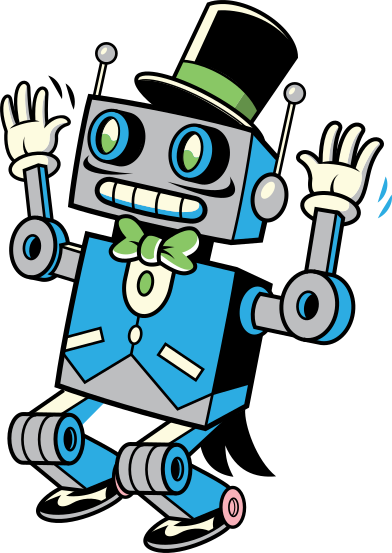

In [5]:
from IPython.display import Image, display
import requests

# download the image data directly
url = "https://www.ros.org/imgs/jazzy_robot.png"
response = requests.get(url)

# display the raw image data
display(Image(data=response.content))


---

## Structure of IPython.display

Conceptually, IPython.display has two main parts:

```
IPython.display
│
├── Display functions
│   ├── display()
│   ├── update_display()
│   ├── clear_output()
│   └── publish_display_data()
│
└── Display object classes
    ├── HTML
    ├── Markdown
    ├── Latex
    ├── Math
    ├── Image
    ├── SVG
    ├── JSON
    ├── Audio
    ├── Video
    └── Javascript
```
The functions send output and the classes define rich objects that know how to represent themselves.

---

## HTML Rendering

For an object to display as HTML, you only need to add a _repr_html_ method to its class. For example, a backtest report can render itself as a metrics table:

In [6]:
class BacktestReport:
    def __init__(self, metrics):
        self.metrics = metrics  # dict, e.g. {"CAGR": 0.18, "Sharpe": 1.4}

    def _repr_html_(self):
        row = "<tr> <td>%s</td> <td>%s</td> </tr>"
        rows = "\n".join([row % (k, v) for k, v in self.metrics.items()])
        return "<table> <tr><th>Metric</th><th>Value</th></tr> %s</table>" % rows

BacktestReport({"CAGR": 0.18, "Sharpe": 1.4, "Max drawdown": -0.12})

Metric,Value
CAGR,0.18
Sharpe,1.4
Max drawdown,-0.12


---

## Math

Jupyter recognizes several other representation methods, including `_repr_png_`, `_repr_svg_`, and `_repr_latex_`. The first two generate graphics in the output cell (Matplotlib uses them). The Math class uses `_repr_latex_` to render mathematical formulas, which is useful for stating exact definitions:

In [7]:
from IPython.display import Math

Math(r'\mathrm{Sharpe} = \frac{\mathbb{E}[R_p - R_f]}{\sigma_p}')

<IPython.core.display.Math object>

Any class can implement `_repr_latex_` to display itself as a formula. For example, a Sharpe-ratio object that prints its own equation with the numbers filled in:

In [8]:
class SharpeRatio:
    def __init__(self, excess_return, volatility):
        self.excess_return = excess_return
        self.volatility = volatility

    def _repr_latex_(self):
        return r"$\mathrm{Sharpe} = \frac{%.2f}{%.2f} = %.2f$" % \
            (self.excess_return, self.volatility,
             self.excess_return / self.volatility)

SharpeRatio(0.08, 0.16)

---

## Interactive Widgets

The notebook can build UI elements (widgets) that maintain two-way communication between the browser frontend and the Python kernel. The interact function from ipywidgets is the simplest entry point: give it a function and a control for each argument, and it re-runs the function (updating the output) whenever you move the control. Reusing the `equity_curve` function from earlier, we can attach a slider to the `daily-return` parameter and watch the equity curve update live:

In [9]:
import matplotlib.pyplot as plt

from ipywidgets import interact
import ipywidgets as widgets

def equity_curve(r, n):
    """
    Return the first n points of an equity curve that compounds a
    constant per-step return r, starting from 1.0.
    """
    e = [1.0] * n
    for i in range(1, n):
        e[i] = e[i - 1] * (1 + r)
    return e

# print(equity_curve(0.01, 10))

def plot_equity(r):
    e = equity_curve(r, 250)
    fig, ax = plt.subplots()
    ax.plot(e, color='black', lw=2, label="daily return = %.3f" % r)
    ax.set_xlabel("trading day")
    ax.set_ylabel("equity (start = 1.0)")
    ax.legend(loc=2)
    plt.close(fig)
    return fig


interact(plot_equity, r=widgets.FloatSlider(min=-0.01, max=0.01, step=0.001));

interactive(children=(FloatSlider(value=0.0, description='r', max=0.01, min=-0.01, step=0.001), Output()), _do…